<a href="https://colab.research.google.com/github/nicolastibata/MINE_4210_ADL_202620/blob/main/labs/Laboratorio_11/MINE_4210_ADL_202620_L11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![Logo ADL](https://github.com/nicolastibata/MINE_4210_ADL_202620/blob/main/docs/logo.png?raw=true)

# **Laboratorio 11: Modelos multimodales, CLIP y zero-shot**
**Tutor: Nicolás Tibatá**

## **Tabla de Contenido**

[Contexto y objetivos](#scrollTo=R4YrUaE6udsU&line=14&uniqifier=1)<br>
[1. Comprensión de los datos](#scrollTo=VjA8zwzJvmeO&line=1&uniqifier=1)<br>
[2. Preparación de los datos](#scrollTo=kG8XHROzvuEH&line=1&uniqifier=1)<br>
[3. Modelamiento](#scrollTo=wCS6xYiU4YYs&line=1&uniqifier=1)<br>
[4. Evaluación](#scrollTo=nnCc67Uf5urd&line=1&uniqifier=1)<br>
[5. Detección guiada por texto y segmentación prompteable](#scrollTo=52G-zC-3DTEj&line=1&uniqifier=1)<br>
[6. Preguntas](#scrollTo=8Z94PZwqmXeI&line=1&uniqifier=1)<br>

### **Contexto y Objetivos**

**Problema**
- Una empresa de reciclaje clasifica residuos a partir de fotografías, pero las categorías cambian con las regulaciones y **no siempre hay datos etiquetados** para las nuevas. Quiere saber si los modelos fundacionales multimodales permiten clasificar, localizar y recortar residuos **sin entrenar**, usando solo descripciones en lenguaje natural.

**Objetivos**
1. Entender cómo CLIP alinea imágenes y texto en un mismo espacio, usarlo para clasificar de forma **zero-shot** y compararlo con un clasificador supervisado.
2. Usar modelos fundacionales para **detección guiada por texto** (Grounding DINO y YOLO-World) y **segmentación promptable** (SAM), y combinarlos con CLIP en un flujo de varios modelos.



**Datos**

Usaremos el dataset *Garbage Classification V2* (el mismo de los Laboratorios 9 y 10), que puedes consultar [aquí](https://www.kaggle.com/datasets/sumn2u/garbage-classification-v2). Trabajaremos con una **submuestra balanceada** y la **misma partición del Laboratorio 9** para poder comparar con el clasificador supervisado.

*Disclaimer: en el Laboratorio 9 el ViT necesitó etiquetas para entrenar un clasificador y DETR/SegFormer solo conocían las categorías con las que fueron entrenados (COCO, ADE20K). Ahora el vocabulario lo definimos nosotros con texto.*

In [2]:
!pip install transformers accelerate timm kaggle ultralytics -q

In [3]:
import os
import glob
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from PIL import Image

from transformers import (CLIPModel, CLIPProcessor, AutoProcessor,
                          AutoModelForZeroShotObjectDetection, SamModel, SamProcessor)

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from google.colab import userdata

In [4]:
# Definimos nuestras semillas de reproducibilidad
SEED = 71
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device)

Dispositivo: cuda


### **1. Comprensión de los datos**

Para entender cómo traemos los datos desde kaggle pueden revisar este [link](https://www.kaggle.com/discussions/general/51898#520673)

In [5]:
os.environ["KAGGLE_KEY"] = userdata.get('KAGGLE_KEY')
os.environ["KAGGLE_USERNAME"] = userdata.get('KAGGLE_USERNAME')

!kaggle datasets download -d sumn2u/garbage-classification-v2

! unzip -q -o "garbage-classification-v2.zip" -d /content/garbage

Dataset URL: https://www.kaggle.com/datasets/sumn2u/garbage-classification-v2
License(s): MIT
100% 1.07G/1.07G [00:16<00:00, 71.7MB/s]



In [6]:
# Recorremos las carpetas: la etiqueta de cada imagen es el nombre de su carpeta
CLASES = ['battery', 'biological', 'cardboard', 'clothes', 'glass',
          'metal', 'paper', 'plastic', 'shoes', 'trash']
EXTENSIONES = ('.jpg', '.jpeg', '.png')

Total de imágenes: 36777


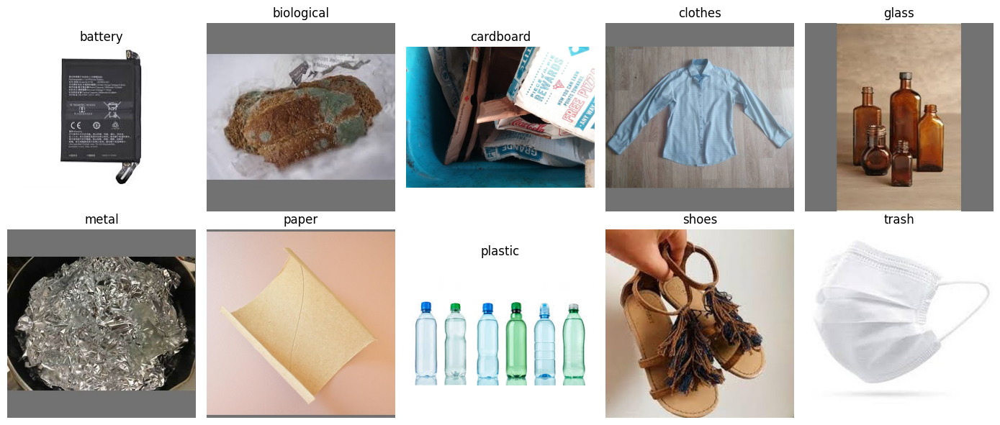

In [7]:
rutas = [p for p in glob.glob('/content/garbage/**/*', recursive=True) if p.lower().endswith(EXTENSIONES)]
df = pd.DataFrame({'path': rutas})
df['label'] = df['path'].apply(lambda p: os.path.basename(os.path.dirname(p)).lower())
df = df[df['label'].isin(CLASES)].reset_index(drop=True)

print("Total de imágenes:", len(df))
df['label'].value_counts()

# Veamos una imagen por clase
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax, clase in zip(axes.ravel(), CLASES):
    ruta = df[df['label'] == clase]['path'].sample(1, random_state=SEED).iloc[0]
    ax.imshow(Image.open(ruta).convert('RGB'))
    ax.set_title(clase)
    ax.axis('off')
plt.tight_layout()
plt.show()

> - Los nombres de las carpetas (`trash`, `biological`) son etiquetas **para humanos**, pero no necesariamente son buenas descripciones para un modelo de lenguaje. Esto será necesario que lo tengamos en cuenta en el zero-shot.


### **2. Preparación de los datos**

Replicamos la preparación del Laboratorio 9: submuestra balanceada de 120 imágenes por clase y la misma partición.

In [8]:
N_POR_CLASE = 120
n = min(N_POR_CLASE, df['label'].value_counts().min())
df_sub = df.groupby('label').sample(n=n, random_state=SEED).reset_index(drop=True)

In [9]:
# Codificamos las etiquetas
label_encoder = LabelEncoder()
df_sub['y'] = label_encoder.fit_transform(df_sub['label'])
classes_names = [str(c) for c in label_encoder.classes_]
for valor_numerico, etiqueta_original in enumerate(classes_names):
    print(f'Valor numérico: {valor_numerico}, Etiqueta original: {etiqueta_original}')

train, test = train_test_split(df_sub, test_size=0.2, stratify=df_sub['y'], random_state=42, shuffle=True)
train, val = train_test_split(train, test_size=0.2, stratify=train['y'], random_state=42, shuffle=True)
train, val, test = train.reset_index(drop=True), val.reset_index(drop=True), test.reset_index(drop=True)

print("Tamaño de datos de entrenamiento:", train.shape)
print("Tamaño de datos de validación:", val.shape)
print("Tamaño de datos de prueba:", test.shape)
y_train, y_val, y_test = train['y'].values, val['y'].values, test['y'].values

Valor numérico: 0, Etiqueta original: battery
Valor numérico: 1, Etiqueta original: biological
Valor numérico: 2, Etiqueta original: cardboard
Valor numérico: 3, Etiqueta original: clothes
Valor numérico: 4, Etiqueta original: glass
Valor numérico: 5, Etiqueta original: metal
Valor numérico: 6, Etiqueta original: paper
Valor numérico: 7, Etiqueta original: plastic
Valor numérico: 8, Etiqueta original: shoes
Valor numérico: 9, Etiqueta original: trash
Tamaño de datos de entrenamiento: (768, 3)
Tamaño de datos de validación: (192, 3)
Tamaño de datos de prueba: (240, 3)


In [10]:
# Descripciones en lenguaje natural de cada clase (este es el "vocabulario" que le daremos al modelo)
NOMBRES_DESC = {
    'battery': 'a used battery',
    'biological': 'food waste',
    'cardboard': 'a piece of cardboard',
    'clothes': 'a piece of clothing',
    'glass': 'a glass bottle or jar',
    'metal': 'a metal can',
    'paper': 'a sheet of paper',
    'plastic': 'a plastic bottle',
    'shoes': 'a pair of shoes',
    'trash': 'general trash',
}
nombres_desc = [NOMBRES_DESC[c] for c in classes_names]

### **3. Modelamiento**

#### **3.1. Anatomía de CLIP**

CLIP tiene **dos codificadores**: uno de imágenes (un ViT, como el del Laboratorio 9) y uno de texto (un Transformer, como los de los Laboratorios 7 y 8). Cada uno produce un vector que se proyecta a un **espacio compartido** y se normaliza. Se entrena con 400 millones de pares imagen-texto de internet con una pérdida contrastiva: dentro de un lote, cada imagen debe parecerse más a *su* texto que a los demás, y viceversa.

Usamos `openai/clip-vit-base-patch32`.




In [11]:
CLIP_NAME = "openai/clip-vit-base-patch32"
clip_proc = CLIPProcessor.from_pretrained(CLIP_NAME)
clip = CLIPModel.from_pretrained(CLIP_NAME).to(device).eval()

print(f"Parámetros totales: {sum(p.numel() for p in clip.parameters())/1e6:.0f}M")
print(f"  - codificador de imágenes: {sum(p.numel() for p in clip.vision_model.parameters())/1e6:.0f}M")
print(f"  - codificador de texto   : {sum(p.numel() for p in clip.text_model.parameters())/1e6:.0f}M")
print(f"Dimensión del espacio compartido: {clip.config.projection_dim}")
print(f"Escala de temperatura (logit_scale): {clip.logit_scale.exp().item():.0f}")

@torch.no_grad()
def emb_imagenes_pil(imgs, batch=64):
    """Embeddings normalizados de una lista de imágenes PIL."""
    feats = []
    for i in range(0, len(imgs), batch):
        x = clip_proc(images=imgs[i:i + batch], return_tensors='pt').to(device)
        f = clip.visual_projection(clip.vision_model(pixel_values=x['pixel_values']).pooler_output)
        feats.append(F.normalize(f, dim=-1).cpu())
    return torch.cat(feats)

def emb_imagenes(rutas_img):
    imgs = [Image.open(p).convert('RGB') for p in rutas_img]
    return emb_imagenes_pil(imgs)

@torch.no_grad()
def emb_textos(textos):
    """Embeddings normalizados de una lista de textos."""
    x = clip_proc(text=textos, return_tensors='pt', padding=True).to(device)
    f = clip.text_projection(clip.text_model(**x).pooler_output)
    return F.normalize(f, dim=-1).cpu()

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

... (3 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Parámetros totales: 151M
  - codificador de imágenes: 87M
  - codificador de texto   : 63M
Dimensión del espacio compartido: 512
Escala de temperatura (logit_scale): 100


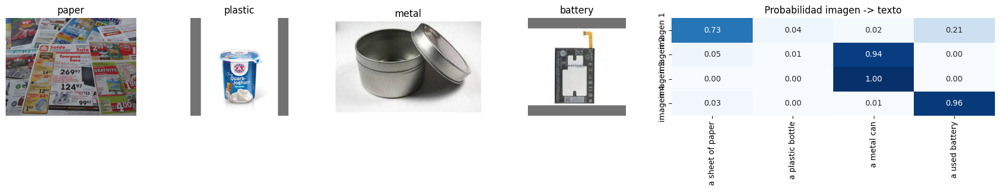

In [12]:
# Similitud entre 4 imágenes de prueba (de clases distintas) y 4 descripciones
muestra = test.groupby('label').head(1).head(4)
imgs_demo = [Image.open(p).convert('RGB') for p in muestra['path']]
textos_demo = [f"a photo of {NOMBRES_DESC[c]}" for c in muestra['label']]

sim = clip.logit_scale.exp().item() * emb_imagenes_pil(imgs_demo) @ emb_textos(textos_demo).T
probs = sim.softmax(dim=1).numpy()   # para cada imagen, distribución sobre los textos

fig, axes = plt.subplots(1, 5, figsize=(18, 3.5), gridspec_kw={'width_ratios': [1, 1, 1, 1, 2.2]})
for ax, im, c in zip(axes[:4], imgs_demo, muestra['label']):
    ax.imshow(im); ax.set_title(c); ax.axis('off')
sns.heatmap(probs, annot=True, fmt=".2f", cmap="Blues", cbar=False, ax=axes[4],
            xticklabels=[t.replace("a photo of ", "") for t in textos_demo],
            yticklabels=[f"imagen {i+1}" for i in range(4)])
axes[4].set_title("Probabilidad imagen -> texto")
plt.tight_layout()
plt.show()

In [13]:
# Veamos la pérdida contrastiva (simétrica) sobre un lote de pares imagen-texto
def perdida_contrastiva(img_emb, txt_emb, escala):
    logits = escala * img_emb @ txt_emb.T
    objetivo = torch.arange(len(logits))
    return (F.cross_entropy(logits, objetivo) + F.cross_entropy(logits.T, objetivo)) / 2

escala = clip.logit_scale.exp().item()

# Lote A: 10 imágenes de 10 clases distintas, cada una con su texto
lote_a = train.groupby('label').head(1)
perd_a = perdida_contrastiva(emb_imagenes(lote_a['path']), emb_textos([f"a photo of {NOMBRES_DESC[c]}" for c in lote_a['label']]), escala)

# Lote B: 10 imágenes de la misma clase, todas con el mismo texto (pares correctos, pero textos repetidos)
lote_b = train[train['label'] == 'plastic'].head(10)
perd_b = perdida_contrastiva(emb_imagenes(lote_b['path']), emb_textos(["a photo of a plastic bottle"] * 10), escala)

print(f"Pérdida con 10 textos distintos : {perd_a.item():.3f}")
print(f"Pérdida con 10 textos idénticos : {perd_b.item():.3f}   (ln 10 = {np.log(10):.3f})")


Pérdida con 10 textos distintos : 1.093
Pérdida con 10 textos idénticos : 3.733   (ln 10 = 2.303)


> - Cuando varios textos del lote son iguales, la pérdida no puede bajar de $\ln(\text{tamaño del lote})$ aunque todos los pares sean correctos: el modelo no tiene forma de distinguirlos. Por eso CLIP se entrena con lotes enormes de pares muy variados.
> - CLIP aprende a **comparar** imágenes y textos en un espacio común; no genera texto ni imágenes.


#### **3.2 Clasificación zero-shot**

Para clasificar sin entrenar, convertimos cada clase en una **frase** (un *prompt*), la codificamos con el codificador de texto y asignamos cada imagen a la frase más cercana en el espacio compartido. Probamos cuatro formas de escribir las clases:

- **A:** el nombre de la carpeta tal cual (`battery`).
- **B:** `a photo of {nombre de la carpeta}.`
- **C:** `a photo of {descripción}.` con las descripciones en lenguaje natural.
- **D:** *ensemble* de varias plantillas con las descripciones (se promedian los embeddings de texto).

**¿Cómo lo aplicamos?**
1. Cada clase se convierte en una frase (*prompt*).
2. El codificador de texto convierte cada frase en un vector de 512.
3. El codificador de imágenes hace lo mismo con cada foto.
4. Para cada foto, calculamos su similitud con los 10 vectores de texto y elegimos el más parecido.

In [14]:
E_train, E_val, E_test = [emb_imagenes(d['path']) for d in (train, val, test)]

print("Embeddings de imagen (train):", tuple(E_train.shape))
print("Embeddings de imagen (val)  :", tuple(E_val.shape))
print("Embeddings de imagen (test) :", tuple(E_test.shape))
print(f"\n-> Cada imagen quedó resumida en un vector de {E_test.shape[1]} números.")

Embeddings de imagen (train): (768, 512)
Embeddings de imagen (val)  : (192, 512)
Embeddings de imagen (test) : (240, 512)

-> Cada imagen quedó resumida en un vector de 512 números.


PASO 1 - Frases (una por clase):
   battery    -> 'a photo of a used battery.'
   biological -> 'a photo of food waste.'
   cardboard  -> 'a photo of a piece of cardboard.'
   clothes    -> 'a photo of a piece of clothing.'
   glass      -> 'a photo of a glass bottle or jar.'
   metal      -> 'a photo of a metal can.'
   paper      -> 'a photo of a sheet of paper.'
   plastic    -> 'a photo of a plastic bottle.'
   shoes      -> 'a photo of a pair of shoes.'
   trash      -> 'a photo of general trash.'

PASO 2 - Embeddings de texto: (10, 512)  (10 clases x 512 dimensiones)
PASO 3 - Similitudes imagen vs. 10 frases: (10,)
PASO 4 - Predicción: 'paper' | Clase real: 'paper'


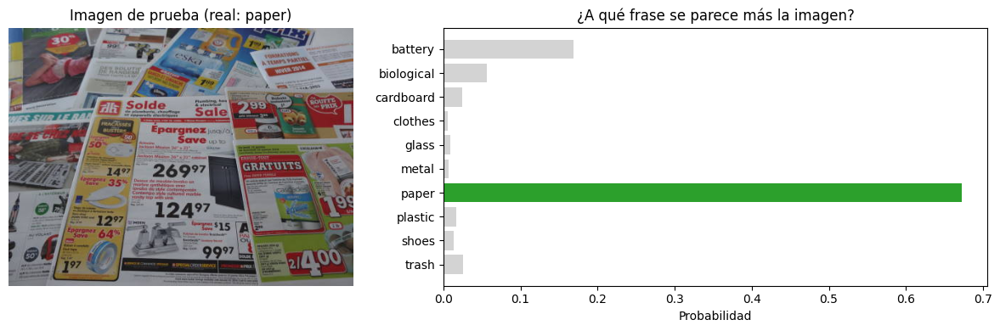

In [15]:
# Veamos el zero-shot paso a paso con una sola imagen de prueba
i = 0
img = Image.open(test['path'].iloc[i]).convert('RGB')
clase_real = classes_names[y_test[i]]

# Convertimos cada cada clase en una frase
prompts = [f"a photo of {d}." for d in nombres_desc]
print("PASO 1 - Frases (una por clase):")
for c, p in zip(classes_names, prompts):
    print(f"   {c:<10} -> '{p}'")

# Codificamos las frases
T = emb_textos(prompts)
print(f"\nPASO 2 - Embeddings de texto: {tuple(T.shape)}  (10 clases x 512 dimensiones)")

# Vemos la similitud coseno entre la imagen y cada frase
sims = E_test[i] @ T.T
print(f"PASO 3 - Similitudes imagen vs. 10 frases: {tuple(sims.shape)}")

# Al final como una clasificación normal, la clase con mayor similitud gana
pred = sims.argmax().item()
print(f"PASO 4 - Predicción: '{classes_names[pred]}' | Clase real: '{clase_real}'")

# Convertimos las similitudes en probabilidades (softmax con la temperatura de CLIP) y graficamos
probs = (clip.logit_scale.exp().item() * sims).softmax(0).numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={'width_ratios': [1, 1.5]})
axes[0].imshow(img); axes[0].axis('off'); axes[0].set_title(f"Imagen de prueba (real: {clase_real})")
colores = ['tab:green' if c == pred else 'lightgray' for c in range(len(classes_names))]
axes[1].barh(classes_names, probs, color=colores)
axes[1].invert_yaxis()
axes[1].set_xlabel("Probabilidad")
axes[1].set_title("¿A qué frase se parece más la imagen?")
plt.tight_layout()
plt.show()

In [16]:
E_train, E_val, E_test = [emb_imagenes(d['path']) for d in (train, val, test)]
print("Embeddings de imagen:", tuple(E_test.shape))

def zero_shot(E_img, plantillas, nombres):
    """Clasifica por similitud con los textos de cada clase (promedio sobre plantillas)."""
    # Para cada plantilla, generamos una frase por clase y la codificamos -> (n_plantillas, 10, 512)
    T = torch.stack([emb_textos([p.format(nom) for nom in nombres]) for p in plantillas])
    # Si hay varias plantillas (ensemble), promediamos sus embeddings
    T = T.mean(0)
    # Re-normalizamos
    T = F.normalize(T, dim=-1)
    # Similitud de cada imagen con cada clase
    logits = E_img @ T.T
    # Y generamos la predicción con las clase más parecida
    return logits.argmax(1).numpy(), logits

PLANTILLAS_D = [
    "a photo of {}.",
    "a picture of {}, a type of household waste.",
    "a close-up photo of {}.",
    "{} on a plain background.",
    "a low resolution photo of {}.",
]

variantes = {
    "A: nombre de carpeta":         (["{}"], classes_names),
    "B: 'a photo of' + carpeta":    (["a photo of {}."], classes_names),
    "C: 'a photo of' + descripción": (["a photo of {}."], nombres_desc),
    "D: ensemble + descripción":    (PLANTILLAS_D, nombres_desc),
}
pred_zs = {nombre: zero_shot(E_test, pl, nom)[0] for nombre, (pl, nom) in variantes.items()}

Embeddings de imagen: (240, 512)


Así se escribe la clase 'battery' en cada variante:

A: nombre de carpeta
     'battery'

B: 'a photo of' + carpeta
     'a photo of battery.'

C: 'a photo of' + descripción
     'a photo of a used battery.'

D: ensemble + descripción
     'a photo of a used battery.'
     'a picture of a used battery, a type of household waste.'
     'a close-up photo of a used battery.'
     'a used battery on a plain background.'
     'a low resolution photo of a used battery.'



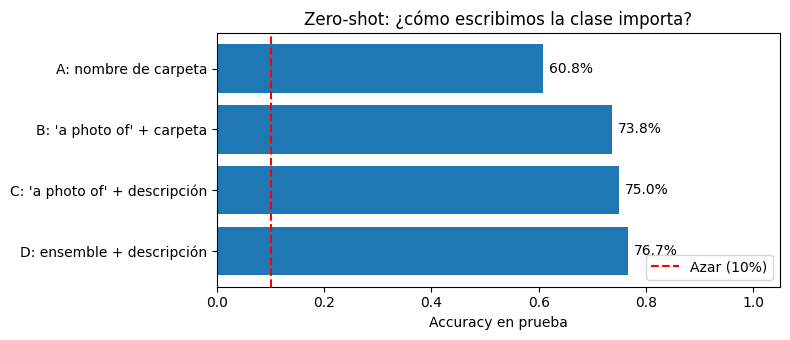

In [17]:
# Veamos el ejemplo de nuestras frases con la clase 'battery'
idx_bat = classes_names.index('battery')
print("Así se escribe la clase 'battery' en cada variante:\n")
for nombre, (pl, nom) in variantes.items():
    print(f"{nombre}")
    for p in pl:
        print(f"     '{p.format(nom[idx_bat])}'")
    print()

# Veamos el resultado de cada variante
acc_var = {n: np.mean(p == y_test) for n, p in pred_zs.items()}

plt.figure(figsize=(8, 3.5))
barras = plt.barh(list(acc_var.keys()), list(acc_var.values()), color='tab:blue')
plt.axvline(1 / len(classes_names), color='red', linestyle='--', label='Azar (10%)')
plt.gca().invert_yaxis()
for b, v in zip(barras, acc_var.values()):
    plt.text(v + 0.01, b.get_y() + b.get_height() / 2, f"{v:.1%}", va='center')
plt.xlim(0, 1.05)
plt.xlabel("Accuracy en prueba")
plt.title("Zero-shot: ¿cómo escribimos la clase importa?")
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

#### **3.3 Del zero-shot al few-shot: sonda lineal**

Si tenemos algunas imágenes etiquetadas, podemos entrenar una **regresión logística** sobre los embeddings de CLIP (una *sonda lineal*). Veamos cuántas imágenes por clase hacen falta para superar al zero-shot.

In [18]:
# Elegimos C con validación usando todo el entrenamiento
mejor_C, mejor_acc = None, -1
for C in (0.1, 1, 10, 100):
    acc = LogisticRegression(C=C, max_iter=3000).fit(E_train.numpy(), y_train).score(E_val.numpy(), y_val)
    if acc > mejor_acc:
        mejor_C, mejor_acc = C, acc
print(f"Mejor C={mejor_C} (accuracy en validación: {mejor_acc:.3f})")

sonda = LogisticRegression(C=mejor_C, max_iter=3000).fit(E_train.numpy(), y_train)
pred_sonda = sonda.predict(E_test.numpy())

Mejor C=10 (accuracy en validación: 0.911)


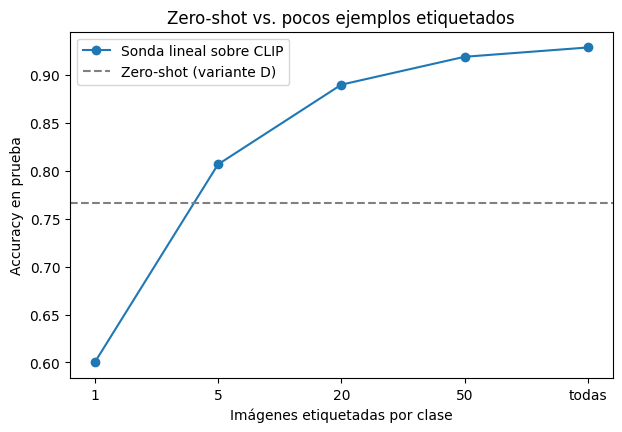

In [19]:
# Curva de imágenes etiquetadas por clase vs. accuracy
ks = [1, 5, 20, 50, None]
acc_k = []
for k in ks:
    accs = []
    for rep in range(3):
        rng = np.random.RandomState(rep)
        idx = np.arange(len(y_train)) if k is None else np.concatenate(
            [rng.choice(np.where(y_train == c)[0], k, replace=False) for c in range(len(classes_names))])
        clf = LogisticRegression(C=mejor_C, max_iter=3000).fit(E_train.numpy()[idx], y_train[idx])
        accs.append(clf.score(E_test.numpy(), y_test))
    acc_k.append(np.mean(accs))

acc_zs_mejor = np.mean(pred_zs["D: ensemble + descripción"] == y_test)
plt.figure(figsize=(7, 4.5))
plt.plot([str(k) if k else "todas" for k in ks], acc_k, marker='o', label="Sonda lineal sobre CLIP")
plt.axhline(acc_zs_mejor, color='gray', linestyle='--', label="Zero-shot (variante D)")
plt.xlabel("Imágenes etiquetadas por clase")
plt.ylabel("Accuracy en prueba")
plt.title("Zero-shot vs. pocos ejemplos etiquetados")
plt.legend()
plt.show()

### **4. Evaluación**

Usamos las mismas métricas del Laboratorio 9: accuracy, macro-F1 y **recall de la peor clase**, para comparar directamente con el clasificador supervisado.

In [20]:
def evaluar(nombre, y_true, y_pred):
    recalls = recall_score(y_true, y_pred, labels=list(range(len(classes_names))), average=None, zero_division=0)
    peor = int(np.argmin(recalls))
    return {
        "modelo": nombre,
        "accuracy": float(np.mean(y_true == y_pred)),
        "macro_F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_peor_clase": recalls[peor],
        "peor_clase": classes_names[peor],
}

,accuracy,macro_F1,recall_peor_clase,peor_clase
modelo,,,,
ViT-base + LogReg (Lab 9),0.920,0.920,0.830,trash
Zero-shot A: nombre de carpeta,0.608,0.585,0.083,battery
Zero-shot B: 'a photo of' + carpeta,0.738,0.721,0.167,trash
Zero-shot C: 'a photo of' + descripción,0.750,0.712,0.042,trash
Zero-shot D: ensemble + descripción,0.767,0.729,0.042,trash
Sonda lineal CLIP (todo el train),0.929,0.929,0.792,glass


              precision    recall  f1-score   support

     battery       0.83      1.00      0.91        24
  biological       0.77      0.96      0.85        24
   cardboard       0.81      0.54      0.65        24
     clothes       0.75      1.00      0.86        24
       glass       0.83      0.79      0.81        24
       metal       0.63      0.92      0.75        24
       paper       0.86      0.79      0.83        24
     plastic       0.59      0.67      0.63        24
       shoes       0.92      0.96      0.94        24
       trash       1.00      0.04      0.08        24

    accuracy                           0.77       240
   macro avg       0.80      0.77      0.73       240
weighted avg       0.80      0.77      0.73       240



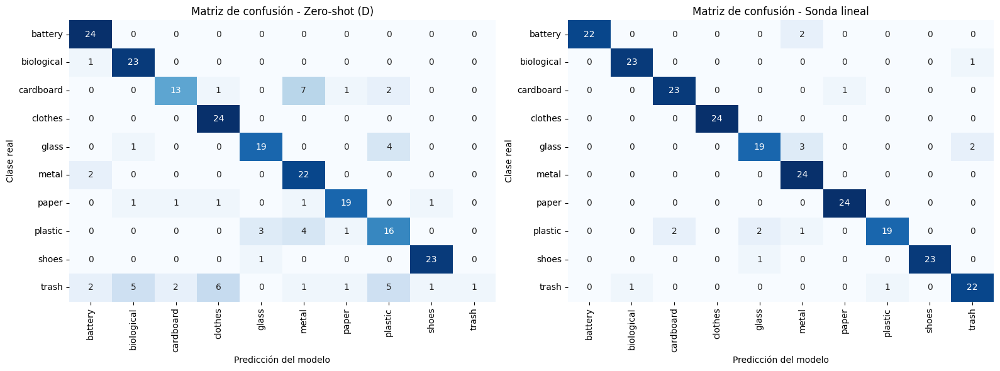

In [21]:
# Tomemos como base el ViT congelado + regresión logística del Laboratorio 9.
baseline_vit = {"modelo": "ViT-base + LogReg (Lab 9)", "accuracy": 0.92, "macro_F1": 0.92,
                "recall_peor_clase": 0.83, "peor_clase": 'trash'}

filas = [baseline_vit]
for nombre, pred in pred_zs.items():
    filas.append(evaluar(f"Zero-shot {nombre}", y_test, pred))
filas.append(evaluar("Sonda lineal CLIP (todo el train)", y_test, pred_sonda))

tabla = pd.DataFrame(filas).set_index("modelo")
display(tabla.round(3))

mejor_variante = "D: ensemble + descripción"
print(classification_report(y_test, pred_zs[mejor_variante], target_names=classes_names, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (titulo, pred) in zip(axes, [("Zero-shot (D)", pred_zs[mejor_variante]), ("Sonda lineal", pred_sonda)]):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes_names,
                yticklabels=classes_names, ax=ax, cbar=False)
    ax.set_title(f"Matriz de confusión - {titulo}")
    ax.set_xlabel("Predicción del modelo")
    ax.set_ylabel("Clase real")
plt.tight_layout()
plt.show()

Errores del zero-shot (D): 56 de 240


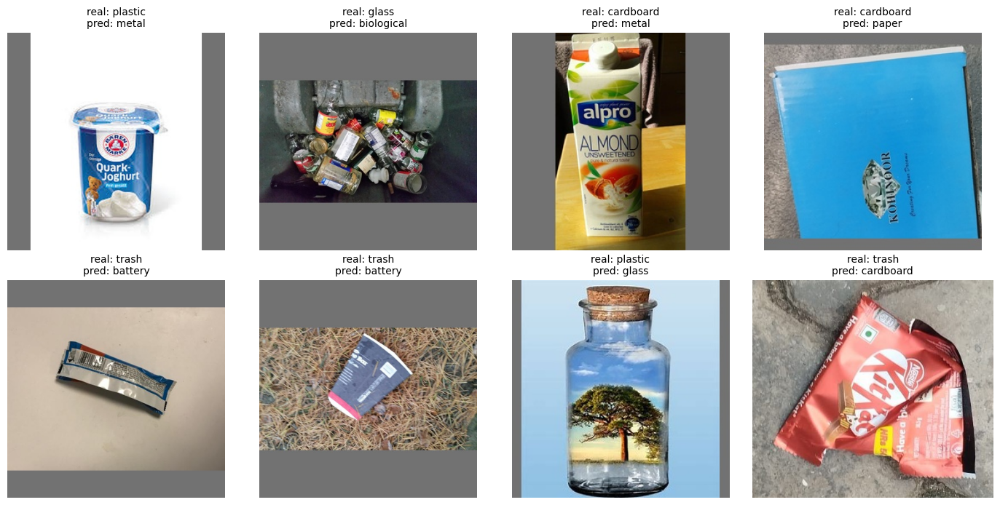

In [22]:
# Veamos algunas imágenes mal clasificadas en zero-shot
errores = np.where(pred_zs[mejor_variante] != y_test)[0]
print(f"Errores del zero-shot (D): {len(errores)} de {len(y_test)}")
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, idx in zip(axes.ravel(), errores[:8]):
    ax.imshow(Image.open(test['path'].iloc[idx]).convert('RGB'))
    ax.set_title(f"real: {classes_names[y_test[idx]]}\npred: {classes_names[pred_zs[mejor_variante][idx]]}", fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

### **5. Detección guiada por texto y segmentación promptable**

#### **5.1. Detección con vocabulario abierto: Grounding DINO y YOLO-World**

**Grounding DINO** recibe una imagen y un **texto libre** (por ejemplo, `"a pair of shoes."`) y devuelve las cajas de los objetos que corresponden a esa descripción. A diferencia de DETR (Laboratorio 9), no está limitado a un vocabulario fijo.

In [32]:
DINO_NAME = "IDEA-Research/grounding-dino-tiny"
proc_dino = AutoProcessor.from_pretrained(DINO_NAME)
dino = AutoModelForZeroShotObjectDetection.from_pretrained(DINO_NAME).to(device).eval()

@torch.no_grad()
def detectar(img, texto, umbral_caja=0.3, umbral_texto=0.25):
    """Devuelve (cajas [x0,y0,x1,y1], puntajes, frases) para las partes de la imagen que coinciden con el texto."""
    inputs = proc_dino(images=img, text=texto, return_tensors='pt').to(device)
    outputs = dino(**inputs)
    kw = dict(text_threshold=umbral_texto, target_sizes=[img.size[::-1]])
    try:
        res = proc_dino.post_process_grounded_object_detection(outputs, inputs.input_ids, threshold=umbral_caja, **kw)[0]
    except TypeError:   # versiones anteriores de transformers usan otro nombre de argumento
        res = proc_dino.post_process_grounded_object_detection(outputs, inputs.input_ids, box_threshold=umbral_caja, **kw)[0]
    frases = res.get('text_labels', res['labels'])
    return res['boxes'].cpu().numpy(), res['scores'].cpu().numpy(), list(frases)

def dibujar_cajas(ax, img, cajas, puntajes, frases, color='red', fs=9, lw=2):
    ax.imshow(img)
    for c, s, f in zip(cajas, puntajes, frases):
        ax.add_patch(patches.Rectangle((c[0], c[1]), c[2] - c[0], c[3] - c[1], fill=False, edgecolor=color, linewidth=lw))
        ax.text(c[0], c[1], f"{f} {s:.2f}", color='white', bbox=dict(facecolor=color, alpha=0.7, pad=1), fontsize=fs)
    ax.axis('off')

Loading weights:   0%|          | 0/978 [00:00<?, ?it/s]

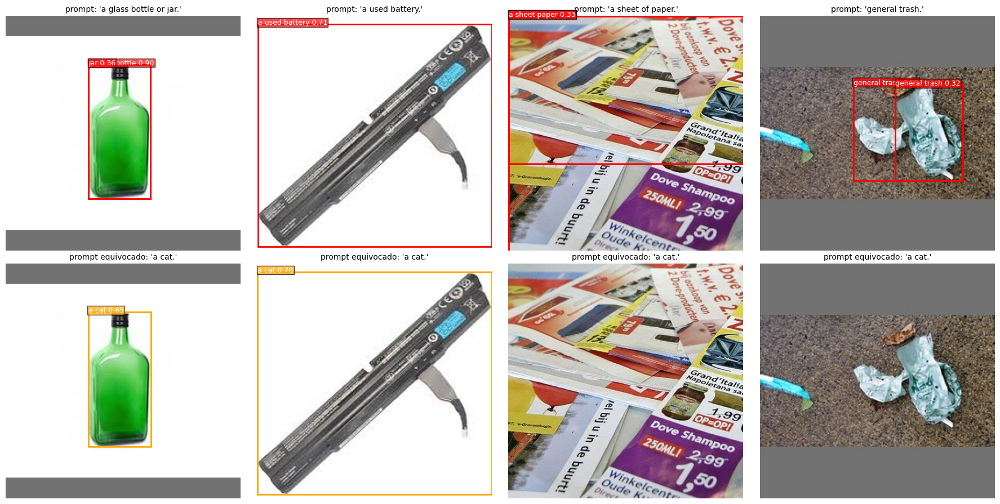

In [33]:
# Veamos la misma imagen con el prompt correcto (fila superior) y con un prompt equivocado (fila inferior)
demo = test.sample(4, random_state=SEED)
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for j, (_, fila) in enumerate(demo.iterrows()):
    img = Image.open(fila['path']).convert('RGB')
    texto_ok = f"{NOMBRES_DESC[fila['label']]}."
    dibujar_cajas(axes[0, j], img, *detectar(img, texto_ok))
    axes[0, j].set_title(f"prompt: '{texto_ok}'", fontsize=10)
    dibujar_cajas(axes[1, j], img, *detectar(img, "a cat."), color='orange')
    axes[1, j].set_title("prompt equivocado: 'a cat.'", fontsize=10)
plt.tight_layout()
plt.show()

**YOLO-World** es otro detector de vocabulario abierto pero con una metodología distinta: es una arquitectura **convolucional tipo YOLO** (no un Transformer) que usa el **codificador de texto de CLIP** para convertir las frases en embeddings, y está diseñada para **tiempo real**. Además permite que seteemos el vocabulario de antemano (`set_classes`), de modo que el texto se codifica una sola vez.

Comparamos ambos detectores con **las mismas imágenes y las mismas frases cortas**.



In [34]:
from ultralytics import YOLOWorld

yolo_w = YOLOWorld("yolov8s-worldv2.pt")
dev_yolo = 0 if torch.cuda.is_available() else "cpu"

FRASES_CORTAS = {
    'battery': 'battery', 'biological': 'food waste', 'cardboard': 'cardboard', 'clothes': 'clothing',
    'glass': 'glass bottle', 'metal': 'metal can', 'paper': 'paper', 'plastic': 'plastic bottle',
    'shoes': 'shoes', 'trash': 'trash',
}

def detectar_yolow(img, frases, conf=0.1):
    """Devuelve (cajas [x0,y0,x1,y1], puntajes, frases) con YOLO-World para una lista de frases cortas."""
    yolo_w.set_classes(frases)   # codifica el texto con CLIP
    r = yolo_w.predict(img, conf=conf, verbose=False, device=dev_yolo)[0]
    cajas = r.boxes.xyxy.cpu().numpy()
    puntajes = r.boxes.conf.cpu().numpy()
    etiquetas = [frases[int(c)] for c in r.boxes.cls.cpu().numpy()]
    return cajas, puntajes, etiquetas

def sincronizar():
    if device == "cuda":
        torch.cuda.synchronize()

detectores = {
    "Grounding DINO": lambda im, frase: detectar(im, f"{frase}."),
    "YOLO-World":     lambda im, frase: detectar_yolow(im, [frase]),
}

# Hacemos la llamada a nuestro modelo
img0 = Image.open(demo['path'].iloc[0]).convert('RGB')
for fn in detectores.values():
    fn(img0, "shoes")

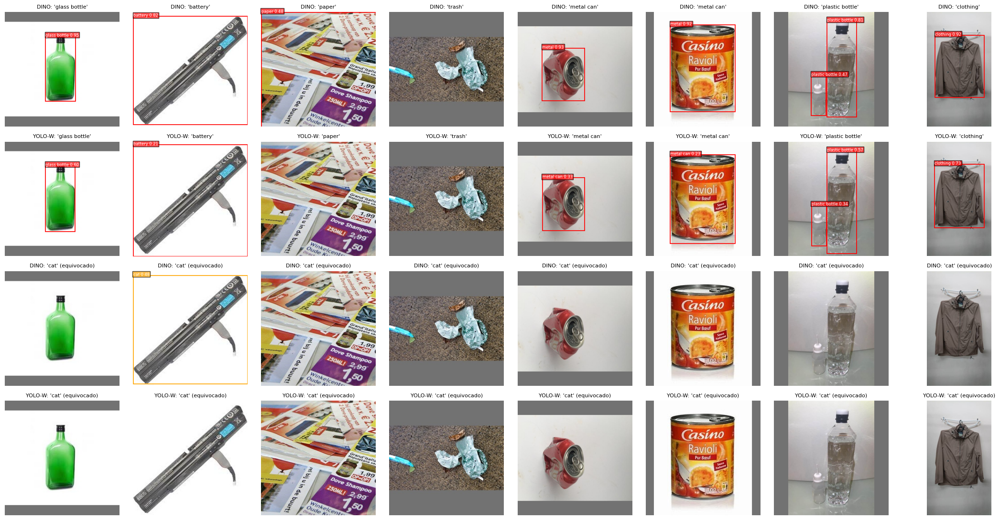

,parametros_M,seg_por_imagen,cajas_prompt_correcto (prom.),cajas_prompt_equivocado (prom.)
Grounding DINO,172.251,0.406,1.000,0.125
YOLO-World,12.760,4.319,0.875,0.000


In [35]:
N_DEMO_DET = 8
demo_det = test.sample(N_DEMO_DET, random_state=SEED)

# Filas: DINO (con el prompt correcto), YOLO-World (con el prompt correcto),
# DINO ('cat'), YOLO-World ('cat'), es decir prompts incorrectos
corto = {"Grounding DINO": "DINO", "YOLO-World": "YOLO-W"}
fig, axes = plt.subplots(4, N_DEMO_DET, figsize=(2.7 * N_DEMO_DET, 11))
stats = {nombre: {"seg": [], "cajas_ok": [], "cajas_cat": []} for nombre in detectores}
for j, (_, fila) in enumerate(demo_det.iterrows()):
    img = Image.open(fila['path']).convert('RGB')
    frase = FRASES_CORTAS[fila['label']]
    for i, (nombre, fn) in enumerate(detectores.items()):
        sincronizar(); t0 = time.time()
        res_ok = fn(img, frase)
        sincronizar(); stats[nombre]["seg"].append(time.time() - t0)
        res_cat = fn(img, "cat")
        stats[nombre]["cajas_ok"].append(len(res_ok[0]))
        stats[nombre]["cajas_cat"].append(len(res_cat[0]))
        dibujar_cajas(axes[i, j], img, *res_ok, fs=6, lw=1.2)
        axes[i, j].set_title(f"{corto[nombre]}: '{frase}'", fontsize=8)
        dibujar_cajas(axes[2 + i, j], img, *res_cat, color='orange', fs=6, lw=1.2)
        axes[2 + i, j].set_title(f"{corto[nombre]}: 'cat' (equivocado)", fontsize=8)
plt.tight_layout()
plt.show()

params_det = {"Grounding DINO": sum(p.numel() for p in dino.parameters()),
              "YOLO-World": sum(p.numel() for p in yolo_w.model.parameters())}
tabla_det = pd.DataFrame({
    nombre: {"parametros_M": params_det[nombre] / 1e6,
             "seg_por_imagen": np.mean(st["seg"]),
             "cajas_prompt_correcto (prom.)": np.mean(st["cajas_ok"]),
             "cajas_prompt_equivocado (prom.)": np.mean(st["cajas_cat"])}
    for nombre, st in stats.items()}).T
tabla_det.round(3)

#### **5.2. Segmentación promptable: SAM**

**SAM** (*Segment Anything Model*) recibe una imagen y un **prompt espacial** (un punto o una caja) y devuelve la máscara del objeto señalado. SAM no sabe **qué** es el objeto, solo **dónde** termina, por lo tanto no produce etiquetas. Probamos dos prompts: un punto en el centro de la imagen y la caja que entrega Grounding DINO.

In [ ]:
SAM_NAME = "facebook/sam-vit-base"
proc_sam = SamProcessor.from_pretrained(SAM_NAME)
sam = SamModel.from_pretrained(SAM_NAME).to(device).eval()

@torch.no_grad()
def segmentar(img, punto=None, caja=None):
    """Devuelve (máscara booleana HxW, puntaje IoU estimado) para un prompt de punto [x,y] o de caja [x0,y0,x1,y1]."""
    kw = {}
    if punto is not None:
        kw['input_points'] = [[[list(map(float, punto))]]]
    if caja is not None:
        kw['input_boxes'] = [[list(map(float, caja))]]
    inputs = proc_sam(img, return_tensors='pt', **kw).to(device)
    outputs = sam(**inputs)
    masks = proc_sam.image_processor.post_process_masks(
        outputs.pred_masks.cpu(), inputs['original_sizes'].cpu(), inputs['reshaped_input_sizes'].cpu())[0]
    scores = outputs.iou_scores.cpu()[0, 0]          # SAM propone 3 máscaras; nos quedamos con la de mayor IoU estimado
    mejor = int(scores.argmax())
    return masks[0, mejor].numpy(), float(scores[mejor])

def superponer(img, mascara, color=(255, 0, 0), alpha=0.55):
    base = np.array(img).astype(float)
    base[mascara] = (1 - alpha) * base[mascara] + alpha * np.array(color)
    return base.astype(np.uint8)

preprocessor_config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/6.57k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  375MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

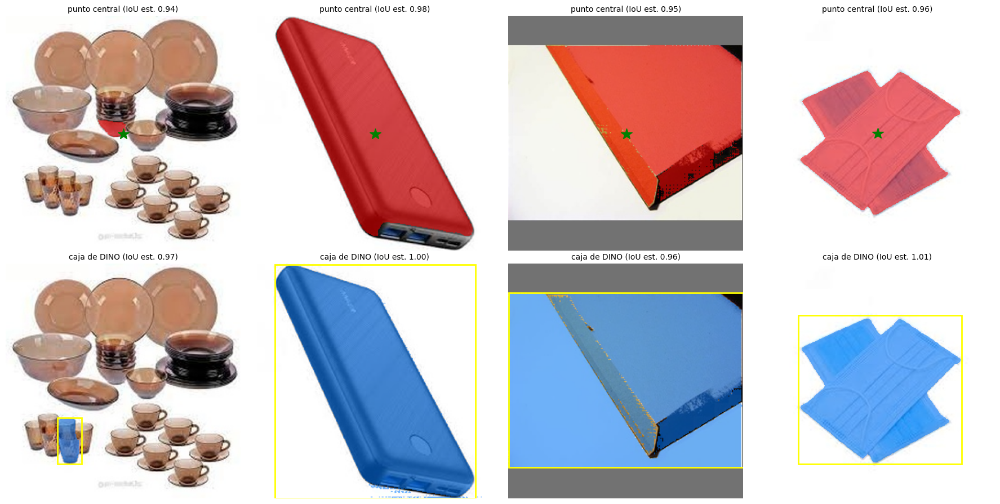

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for j, (_, fila) in enumerate(demo.iterrows()):
    img = Image.open(fila['path']).convert('RGB')
    w, h = img.size
    # a) prompt de punto en el centro
    m_pt, s_pt = segmentar(img, punto=(w / 2, h / 2))
    axes[0, j].imshow(superponer(img, m_pt)); axes[0, j].plot(w / 2, h / 2, 'g*', markersize=15)
    axes[0, j].set_title(f"punto central (IoU est. {s_pt:.2f})", fontsize=10); axes[0, j].axis('off')
    # b) prompt de caja de Grounding DINO
    cajas, puntajes, _ = detectar(img, f"{NOMBRES_DESC[fila['label']]}.")
    if len(cajas):
        caja = cajas[puntajes.argmax()]
        m_bx, s_bx = segmentar(img, caja=caja)
        axes[1, j].imshow(superponer(img, m_bx, color=(0, 120, 255)))
        axes[1, j].add_patch(patches.Rectangle((caja[0], caja[1]), caja[2] - caja[0], caja[3] - caja[1],
                                               fill=False, edgecolor='yellow', linewidth=2))
        axes[1, j].set_title(f"caja de DINO (IoU est. {s_bx:.2f})", fontsize=10)
    else:
        axes[1, j].imshow(img); axes[1, j].set_title("DINO no detectó nada", fontsize=10)
    axes[1, j].axis('off')
plt.tight_layout()
plt.show()

#### **5.3. Componiendo modelos fundacionales: texto → caja → máscara → CLIP**

Combinamos los tres modelos: Grounding DINO localiza "un objeto", SAM recorta su silueta, pintamos el fondo de gris y CLIP clasifica el recorte. La hipótesis es que **quitar el fondo ayuda** a clasificar. La probamos sobre un subconjunto de 100 imágenes de prueba (10 por clase).

In [ ]:
def aislar_objeto(img, texto="an object."):
    """Devuelve (imagen con fondo gris, bool de si se detectó un objeto)."""
    cajas, puntajes, _ = detectar(img, texto, umbral_caja=0.25, umbral_texto=0.2)
    if len(cajas) == 0:
        return img, False
    mascara, _ = segmentar(img, caja=cajas[puntajes.argmax()])
    base = np.array(img)
    return Image.fromarray(np.where(mascara[..., None], base, 128).astype(np.uint8)), True

sub = test.groupby('label').head(10).reset_index()    # conserva el índice original en la columna 'index'
imgs_orig = [Image.open(p).convert('RGB') for p in sub['path']]

t0 = time.time()
resultados = [aislar_objeto(im) for im in imgs_orig]
imgs_aisladas = [r[0] for r in resultados]
n_detectados = sum(r[1] for r in resultados)
print(f"Objetos detectados: {n_detectados} de {len(sub)} | tiempo: {time.time() - t0:.0f} s")

y_sub = sub['y'].values
pred_orig, _ = zero_shot(emb_imagenes_pil(imgs_orig), PLANTILLAS_D, nombres_desc)
pred_aisl, _ = zero_shot(emb_imagenes_pil(imgs_aisladas), PLANTILLAS_D, nombres_desc)

tabla_comp = pd.DataFrame([evaluar("Zero-shot, imagen completa", y_sub, pred_orig),
                           evaluar("Zero-shot, objeto aislado (DINO + SAM)", y_sub, pred_aisl)]).set_index("modelo")
tabla_comp.round(3)

/usr/local/lib/python3.13/dist-packages/transformers/models/grounding_dino/processing_grounding_dino.py:89: FutureWarning: The key `labels` is will return integer ids in `GroundingDinoProcessor.post_process_grounded_object_detection` output since v4.51.0. Use `text_labels` instead to retrieve string object names.
  warnings.warn(self.message, FutureWarning)


Objetos detectados: 100 de 100 | tiempo: 88 s


,accuracy,macro_F1,recall_peor_clase,peor_clase
modelo,,,,
"Zero-shot, imagen completa",0.75,0.712,0.1,trash
"Zero-shot, objeto aislado (DINO + SAM)",0.69,0.668,0.1,trash


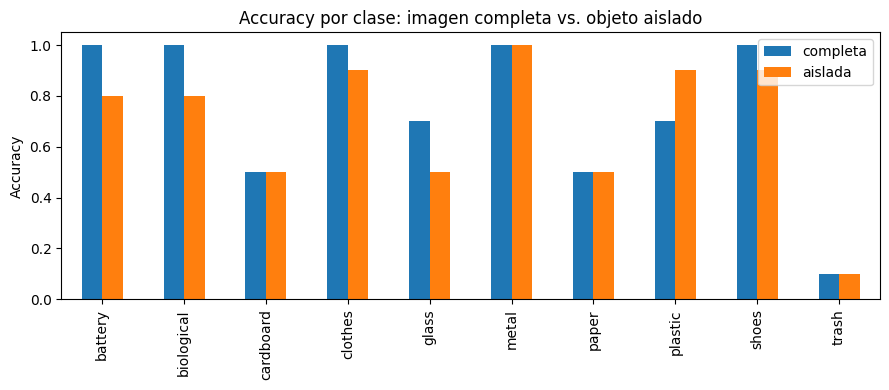

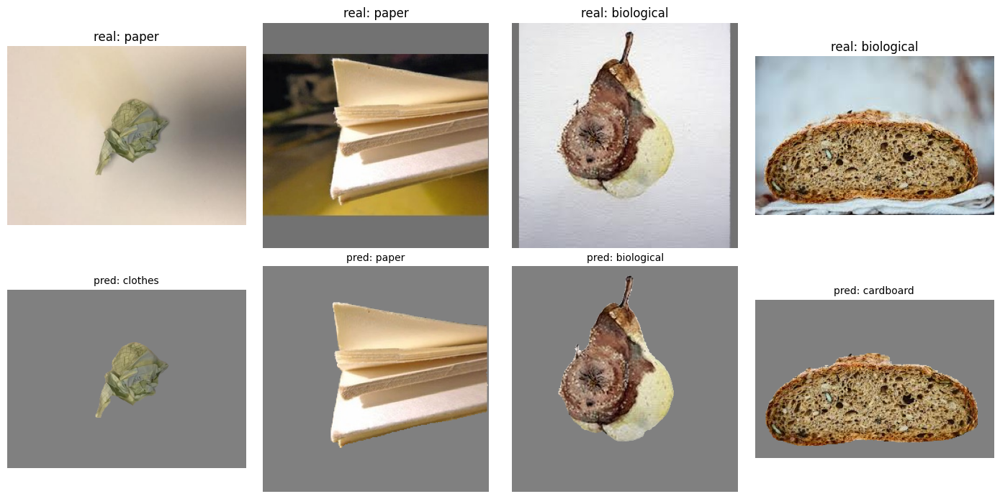

In [ ]:
# Efecto por clase y ejemplos
acc_clase = pd.DataFrame({"completa": [np.mean(pred_orig[y_sub == c] == c) for c in range(len(classes_names))],
                          "aislada": [np.mean(pred_aisl[y_sub == c] == c) for c in range(len(classes_names))]},
                         index=classes_names)
acc_clase.plot.bar(figsize=(9, 4), title="Accuracy por clase: imagen completa vs. objeto aislado")
plt.ylabel("Accuracy"); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for j, idx in enumerate([0, 10, 20, 30]):
    axes[0, j].imshow(imgs_orig[idx]); axes[0, j].set_title(f"real: {sub['label'][idx]}"); axes[0, j].axis('off')
    axes[1, j].imshow(imgs_aisladas[idx]); axes[1, j].axis('off')
    axes[1, j].set_title(f"pred: {classes_names[pred_aisl[idx]]}", fontsize=10)
plt.tight_layout()
plt.show()

**Cerremos con unas conclusiones:**

- CLIP no "entiende" qué es un residuo: mide **qué tan cerca** está una imagen de una frase en un espacio aprendido de pares imagen-texto de internet. Por eso su resultado depende de cómo se escriben las clases (nombre de carpeta vs. descripción vs. *ensemble* de plantillas).
- El zero-shot no entrena, pero el diseño de los prompts es un hiperparámetro oculto.
- Los modelos fundacionales se **componen**: cada uno resuelve una parte (qué, dónde, qué forma) y sus errores se acumulan. Aislar el objeto puede ayudar o perjudicar según la imagen, y debe medirse en lugar de asumirse.



### **6. Preguntas**

1. **Zero-shot vs. supervisado.** Compara las cuatro variantes de zero-shot, la sonda lineal de CLIP y el ViT del Laboratorio 9 en accuracy, macro-F1 y recall de la peor clase. ¿Cuántas imágenes etiquetadas por clase necesita la sonda lineal para superar al zero-shot (curva de la sección 3.3)? Revisa la matriz de confusión: ¿qué clases se confunden y por qué podría ser (por ejemplo, ¿qué significa `trash` para el modelo de lenguaje)? Propón una modificación (otras descripciones, más plantillas, combinar zero-shot con la sonda), aplícala y compara el macro-F1 y el recall de la peor clase.

2. **Sensibilidad a los prompts y sesgos.** Con la misma imagen y los mismos modelos, evalúa al menos 5 plantillas distintas (individualmente, sin *ensemble*) y reporta la media y la desviación estándar del macro-F1. Prueba además plantillas y nombres de clase **en español** y agrega una clase distractora que no existe en los datos (por ejemplo, `a photo of a cat`). ¿Qué tanto cambian los resultados? ¿Qué te dice esto sobre los datos con los que se entrenó CLIP y sobre la fiabilidad del zero-shot en producción?